# AskAuto - Code Walkthrough

**The whole codebase, piece by piece, in the order it makes sense to learn it.**

Each step says what the file does, what to look at, and then **runs real code** so you can
see it work. The outputs below were produced by actually running each cell against this
repository. None of the cells call Groq, so re-running them is free and works offline.

**To run it yourself:** open this notebook with the project's `.venv` Python as the kernel
(it needs `ipykernel`: `.venv/Scripts/python -m pip install ipykernel`). The first cell
moves to the repository root.

| Step | File(s) | You will learn |
|---|---|---|
| 0 | the map | how the folders fit together |
| 1 | `src/askauto/config.py` | where every setting comes from |
| 2 | `scripts/build_database.py` | the data, and the planted traps |
| 3 | `metadata/*.yaml`, `scripts/build_metadata.py` | the catalogue that beats the traps |
| 4 | `src/askauto/mcp_server/sql_guard.py` | how SQL is validated |
| 5 | `mcp_server/server.py`, `db.py`, `src/askauto/mcp_client.py` | the data boundary |
| 6 | `src/askauto/providers/` | how the LLM is called |
| 7 | `agent/state.py`, `agent/prompts.py` | what the agent knows and says |
| 8 | `agent/literals.py`, `agent/verify.py` | the two deterministic checks |
| 9 | `agent/nodes.py`, `agent/graph.py` | the graph, including retries |
| 10 | `src/askauto/api.py` | the HTTP API |
| 11 | `web/index.html`, `frontend/streamlit_app.py` | the two front ends |
| 12 | `evals/` | proving it works on 25 questions |
| 13 | `tests/` | what each test file proves |
| 14 | `CLAUDE.md`, `.claude/` | how the project was built with Claude Code |
| 15 | all of it | one question traced through every function |

In [ ]:
from IPython.display import SVG, display

STYLE = """<style>
  .bx  { fill:#f6f8fa; stroke:#d0d7de; stroke-width:1; }
  .bxa { fill:#f3f0ff; stroke:#8b7fd4; stroke-width:1; }
  .bxw { fill:#fff8e6; stroke:#d4a72c; stroke-width:1; }
  .bxg { fill:#eaf7ee; stroke:#3fb950; stroke-width:1; }
  .th  { font:600 13px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#1f2328; }
  .ts  { font:400 11px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#656d76; }
  .tl  { font:600 11px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#8250df;
         letter-spacing:.06em; }
  .arr { stroke:#656d76; stroke-width:1.4; fill:none; }
  .arrR{ stroke:#d1242f; stroke-width:1.6; fill:none; stroke-dasharray:5 3; }
  .lbl { font:400 10px -apple-system,Segoe UI,Helvetica,sans-serif; fill:#d1242f; }
</style>
<defs>
  <marker id="a" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6"
          markerHeight="6" orient="auto-start-reverse">
    <path d="M2 1L8 5L2 9" fill="none" stroke="#656d76" stroke-width="1.5"
          stroke-linecap="round" stroke-linejoin="round"/>
  </marker>
  <marker id="ar" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6"
          markerHeight="6" orient="auto-start-reverse">
    <path d="M2 1L8 5L2 9" fill="none" stroke="#d1242f" stroke-width="1.5"
          stroke-linecap="round" stroke-linejoin="round"/>
  </marker>
</defs>"""

def diagram(body, width=720, height=400):
    """Render a self-contained SVG diagram inline."""
    return SVG(f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" '
               f'height="{height}" viewBox="0 0 {width} {height}">'
               f'{STYLE}{body}</svg>')

## Step 0 - The map

Two phases with different rules. **Build time** scripts may open the database directly
(like database migrations). At **runtime**, only `mcp_server/` may.

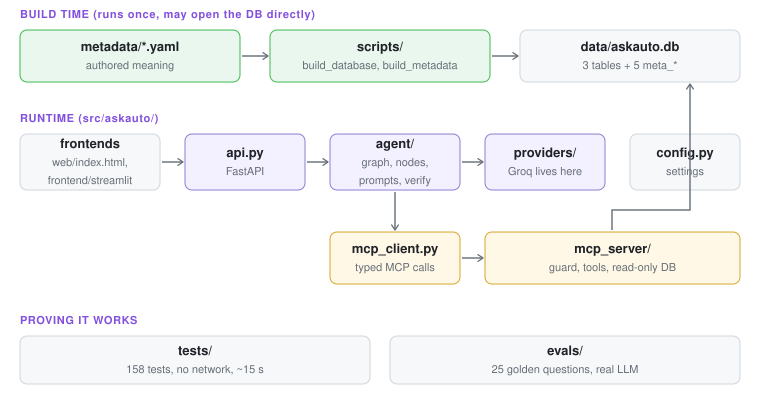

In [1]:
diagram("""
<text class="tl" x="20" y="18" text-anchor="start">BUILD TIME (runs once, may open the DB directly)</text>
<rect x="20" y="30" width="220" height="52" rx="7" class="bxg"/><text class="th" x="130" y="51" text-anchor="middle">metadata/*.yaml</text><text class="ts" x="130" y="69" text-anchor="middle">authored meaning</text>
<rect x="270" y="30" width="220" height="52" rx="7" class="bxg"/><text class="th" x="380" y="51" text-anchor="middle">scripts/</text><text class="ts" x="380" y="69" text-anchor="middle">build_database, build_metadata</text>
<rect x="520" y="30" width="220" height="52" rx="7" class="bx"/><text class="th" x="630" y="51" text-anchor="middle">data/askauto.db</text><text class="ts" x="630" y="69" text-anchor="middle">3 tables + 5 meta_*</text>
<path d="M242 56 L268 56" class="arr" marker-end="url(#a)"/>
<path d="M492 56 L518 56" class="arr" marker-end="url(#a)"/>
<text class="tl" x="20" y="122" text-anchor="start">RUNTIME (src/askauto/)</text>
<rect x="20" y="134" width="140" height="56" rx="7" class="bx"/><text class="th" x="90" y="148" text-anchor="middle">frontends</text><text class="ts" x="90" y="166" text-anchor="middle">web/index.html,</text><text class="ts" x="90" y="184" text-anchor="middle">frontend/streamlit</text>
<rect x="185" y="134" width="120" height="56" rx="7" class="bxa"/><text class="th" x="245" y="157" text-anchor="middle">api.py</text><text class="ts" x="245" y="175" text-anchor="middle">FastAPI</text>
<rect x="330" y="134" width="130" height="56" rx="7" class="bxa"/><text class="th" x="395" y="148" text-anchor="middle">agent/</text><text class="ts" x="395" y="166" text-anchor="middle">graph, nodes,</text><text class="ts" x="395" y="184" text-anchor="middle">prompts, verify</text>
<rect x="485" y="134" width="120" height="56" rx="7" class="bxa"/><text class="th" x="545" y="157" text-anchor="middle">providers/</text><text class="ts" x="545" y="175" text-anchor="middle">Groq lives here</text>
<rect x="630" y="134" width="110" height="56" rx="7" class="bx"/><text class="th" x="685" y="157" text-anchor="middle">config.py</text><text class="ts" x="685" y="175" text-anchor="middle">settings</text>
<path d="M162 162 L183 162" class="arr" marker-end="url(#a)"/>
<path d="M307 162 L328 162" class="arr" marker-end="url(#a)"/>
<path d="M462 162 L483 162" class="arr" marker-end="url(#a)"/>
<rect x="330" y="232" width="130" height="52" rx="7" class="bxw"/><text class="th" x="395" y="253" text-anchor="middle">mcp_client.py</text><text class="ts" x="395" y="271" text-anchor="middle">typed MCP calls</text>
<rect x="485" y="232" width="255" height="52" rx="7" class="bxw"/><text class="th" x="612.5" y="253" text-anchor="middle">mcp_server/</text><text class="ts" x="612.5" y="271" text-anchor="middle">guard, tools, read-only DB</text>
<path d="M395 192 L395 230" class="arr" marker-end="url(#a)"/>
<path d="M462 258 L483 258" class="arr" marker-end="url(#a)"/>
<path d="M612 230 L612 210 L690 210 L690 84" class="arr" marker-end="url(#a)"/>
<text class="tl" x="20" y="324" text-anchor="start">PROVING IT WORKS</text>
<rect x="20" y="336" width="350" height="48" rx="7" class="bx"/><text class="th" x="195" y="355" text-anchor="middle">tests/</text><text class="ts" x="195" y="373" text-anchor="middle">158 tests, no network, ~15 s</text>
<rect x="390" y="336" width="350" height="48" rx="7" class="bx"/><text class="th" x="565" y="355" text-anchor="middle">evals/</text><text class="ts" x="565" y="373" text-anchor="middle">25 golden questions, real LLM</text>
""", width=760, height=400)

In [2]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()
os.chdir(ROOT)
print("Working in:", ROOT.name)

Working in: ask_auto


## Step 1 - Settings: `src/askauto/config.py`

One `Settings` class (pydantic-settings) reads environment variables and `.env`.
Everything configurable lives here: the database path, the model, timeouts. The Groq key
is a `SecretStr`, so it is never printed by accident.

Look at: `Settings`, `resolved_database_path`, `get_settings()` (cached, created once).

In [3]:
from askauto.config import get_settings

settings = get_settings()
print("database:   ", settings.resolved_database_path.relative_to(ROOT))
print("model:      ", settings.groq_model)
print("schema mode:", settings.schema_mode)
print("SQL limits: ", settings.sql_timeout_s, "s timeout,", settings.sql_max_rows, "rows max")
print("Groq key set:", settings.groq_api_key is not None)   # never print the key itself

database:    data\askauto.db
model:       openai/gpt-oss-20b
schema mode: full
SQL limits:  5.0 s timeout, 500 rows max
Groq key set: True


## Step 2 - The data: `scripts/build_database.py`

Creates the 3 business tables from the spec's exact DDL - **with `REFERENCES` clauses**,
because the join graph is read from them later - and fills them with seeded synthetic
data: 20 dealers, 40 vehicles, 5,000 sales from 2023-01-01 to 2026-06-30.

Look at: `DDL`, `DEALERS`, `VEHICLES`, `make_sales()` (all randomness from one seeded
`random.Random`), `verify()` (the PASS/FAIL report) and `fingerprint()`.

The sales table, exactly as created:

In [4]:
import importlib.util

def load_script(name):
    """scripts/ is not a package, so load a script by its path."""
    spec = importlib.util.spec_from_file_location(name, ROOT / "scripts" / f"{name}.py")
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

build_database = load_script("build_database")
print(build_database.DDL[build_database.DDL.index("CREATE TABLE sales"):].strip())

CREATE TABLE sales (
    sale_id         TEXT PRIMARY KEY,
    dealer_id       TEXT NOT NULL REFERENCES dealers(dealer_id),
    vehicle_id      TEXT NOT NULL REFERENCES vehicles(vehicle_id),
    sale_date       TEXT NOT NULL,   -- ISO YYYY-MM-DD
    sale_price      REAL NOT NULL,   -- GROSS, before discount
    discount_amount REAL NOT NULL,
    finance_type    TEXT NOT NULL    -- Loan | Lease | Cash
);


`verify()` checks the built database against the spec. Note trap 1 (gross is 3.5% above
net) and trap 2 (exactly four region spellings) are *checked*, not assumed:

In [5]:
report = build_database.verify(ROOT / "data" / "askauto.db")
for check in report.checks:
    print("PASS" if check.passed else "FAIL", "|", check.name, "|", check.detail[:75])
print("\nfingerprint:", report.fingerprint[:16], "... (same seed = same data, every time)")

PASS | row counts ~20/~40/~5000 | {'dealers': 20, 'vehicles': 40, 'sales': 5000}
PASS | foreign_key_list(sales) has 2 rows | sales.dealer_id -> dealers.dealer_id; sales.vehicle_id -> vehicles.vehicle_
PASS | no foreign key violations | 0 violations
PASS | trap 1: gross exceeds net by 2-5% | gross 173,070,073.75  net 166,989,244.64  gap 3.51%
PASS | trap 2: exactly 4 region spellings | ['Midwest', 'Northeast', 'Southeast', 'West']; 'North East' -> 0 rows
PASS | dealers.region values match spec | Midwest, Northeast, Southeast, West
PASS | dealers.tier values match spec | Flagship, Satellite, Standard
PASS | vehicles.make values match spec | Chevrolet, Ford, Honda, Hyundai, Nissan, Toyota
PASS | vehicles.fuel_type values match spec | Electric, Gasoline, Hybrid
PASS | sales.finance_type values match spec | Cash, Lease, Loan
PASS | sale_date within range | 2023-01-01 .. 2026-06-30
PASS | model_year within 1 year of sale year | 0 bad rows

fingerprint: 14cb404714fb9d9a ... (same seed = same 

## Step 3 - The metadata catalogue: `metadata/*.yaml` + `scripts/build_metadata.py`

This is where the business knowledge lives. The YAML is **written by a person**;
the script merges it with facts read from the database itself:

| Source | Gives | Example |
|---|---|---|
| `PRAGMA table_info` | types, keys, nullability | `sale_price REAL` |
| `PRAGMA foreign_key_list` | the joins | `sales.dealer_id -> dealers` |
| `COUNT(DISTINCT col)` | allowed values (if 25 or fewer) or 3 samples | the 4 regions |
| `metadata/tables.yaml` | what tables and columns *mean* | "sale_price is GROSS" |
| `metadata/glossary.yaml` | business term -> SQL | revenue -> `SUM(sale_price - discount_amount)` |
| `metadata/unanswerable.yaml` | what the data cannot answer | credit scores |

The build **fails loudly** if the YAML names a column that doesn't exist, misses one, or
has a glossary expression that doesn't run. Look at: `validate_authored()`,
`collect_columns()`, `expand_glossary()` (aliases get identical rows).

In [6]:
build_metadata = load_script("build_metadata")
meta = build_metadata.verify(ROOT / "data" / "askauto.db", ROOT / "metadata")

print("Glossary (first 8 of", len(meta.glossary), "rows):")
for g in meta.glossary[:8]:
    print(f"  {g.term:22} {g.sql_expression}")

region = meta.column("dealers", "region")
print("\ndealers.region allowed values:", region.allowed_values)
price = meta.column("sales", "sale_price")
print("sales.sale_price samples (min, median, max):", price.sample_values)
print("sales.sale_price description:", price.description[:70], "...")
print("\njoins:", [f"{j.from_table}.{j.from_column} -> {j.to_table} ({j.cardinality})"
                  for j in meta.joins])

Glossary (first 8 of 15 rows):
  net revenue            SUM(sale_price - discount_amount)
  revenue                SUM(sale_price - discount_amount)
  sales value            SUM(sale_price - discount_amount)
  turnover               SUM(sale_price - discount_amount)
  top line               SUM(sale_price - discount_amount)
  gross revenue          SUM(sale_price)
  units sold             COUNT(*)
  units                  COUNT(*)

dealers.region allowed values: ['Midwest', 'Northeast', 'Southeast', 'West']
sales.sale_price samples (min, median, max): [20305.09, 33106.64, 60503.77]
sales.sale_price description: GROSS transaction price in USD, BEFORE discount. Do not sum this for r ...

joins: ['sales.dealer_id -> dealers (many-to-one)', 'sales.vehicle_id -> vehicles (many-to-one)']


## Step 4 - The SQL guard: `src/askauto/mcp_server/sql_guard.py`

A **pure function** - no database - so it is easy to test and the agent can reuse it.
It parses the SQL with sqlglot and checks the tree, in order:

1. exactly one statement
2. the root is a SELECT (or UNION etc.) - an allowlist, so anything unexpected is rejected
3. every table is `dealers`, `vehicles` or `sales`
4. every column exists (sqlglot's `qualify` against the catalogue)
5. a LIMIT is added, or a larger one is reduced to the cap

Every rejection explains itself, because the agent sends that text back to the LLM.

In [7]:
from askauto.mcp_server.sql_guard import guard_sql

catalog = {}
for c in meta.columns:
    catalog.setdefault(c.table_name, {})[c.column_name] = c.data_type

for sql in [
    "SELECT region FROM dealers",
    "SELECT region FROM dealers LIMIT 10000",
    "DROP TABLE sales",
    "SELECT 1; DROP TABLE sales",
    "SELECT * FROM meta_glossary",
    "SELECT revenue FROM sales",
    "SELECT dealer_id FROM sales JOIN dealers ON sales.dealer_id = dealers.dealer_id",
]:
    result = guard_sql(sql, catalog, max_rows=500)
    print("OK    " if result.ok else "REJECT", sql)
    print("       ->", result.sql if result.ok else result.reason)

OK     SELECT region FROM dealers
       -> SELECT region FROM dealers LIMIT 500
OK     SELECT region FROM dealers LIMIT 10000
       -> SELECT region FROM dealers LIMIT 500
REJECT DROP TABLE sales
       -> Only SELECT or WITH queries are allowed; got DROP.
REJECT SELECT 1; DROP TABLE sales
       -> Exactly one statement is allowed; got 2.
REJECT SELECT * FROM meta_glossary
       -> Table 'meta_glossary' is not queryable. Allowed tables: dealers, sales, vehicles.
REJECT SELECT revenue FROM sales
       -> Column check failed: Column 'revenue' could not be resolved. Line: 1, Col: 14.
REJECT SELECT dealer_id FROM sales JOIN dealers ON sales.dealer_id = dealers.dealer_id
       -> Column 'dealer_id' is ambiguous: it exists in dealers and sales. Qualify it, e.g. dealers.dealer_id.


## Step 5 - The data boundary: `mcp_server/server.py`, `db.py`, `src/askauto/mcp_client.py`

**`server.py`** registers four tools on an `MCPServer`. Its lifespan opens the database
and loads the metadata **once**.

| Tool | Returns |
|---|---|
| `get_schema_context(question)` | everything the prompts need (question ignored in stage 1) |
| `run_sql(sql, limit)` | rows, or a structured error: `rejected`, `sqlite_error` or `timeout` |
| `list_tables()` | table summaries (also used by `/health`) |
| `sample_rows(table, n)` | a few example rows |

**`db.py`** opens SQLite **read-only** and stops any query after 5 seconds.
**`mcp_client.py`** (`McpTools`) is the typed client the agent and API use.

Why errors are *returned* instead of raised: MCP replaces a raised exception's message with
"Error executing tool", and the agent needs the real reason to fix its SQL.

Here the server runs in-process. Note the difference between **zero rows** (valid, just
empty - trap 2!) and **rejected**:

In [8]:
from askauto.mcp_client import McpTools
from askauto.mcp_server.server import create_server

async with McpTools.connect(create_server(settings)) as tools:
    for sql in [
        "SELECT COUNT(*) AS n FROM sales JOIN dealers USING (dealer_id) WHERE region = 'Northeast'",
        "SELECT dealer_name FROM dealers WHERE region = 'North East'",
        "SELECT * FROM meta_glossary",
    ]:
        r = await tools.run_sql(sql)
        print(sql)
        print("   ok:", r.ok, "| rows:", r.rows[:2], "| row_count:", r.row_count,
              "| error:", r.error.kind + ": " + r.error.message if r.error else None)

SELECT COUNT(*) AS n FROM sales JOIN dealers USING (dealer_id) WHERE region = 'Northeast'
   ok: True | rows: [{'n': 1268}] | row_count: 1 | error: None
SELECT dealer_name FROM dealers WHERE region = 'North East'
   ok: True | rows: [] | row_count: 0 | error: None
SELECT * FROM meta_glossary
   ok: False | rows: [] | row_count: 0 | error: rejected: Table 'meta_glossary' is not queryable. Allowed tables: dealers, sales, vehicles.


## Step 6 - Calling the LLM: `src/askauto/providers/`

| File | Job |
|---|---|
| `base.py` | provider-agnostic: `Message`, the 3 call sites and their settings, `LLMProvider` |
| `groq_provider.py` | the **only** file that imports Groq; retries and error handling |
| `smoke.py` | `python -m askauto.providers.smoke` - a live check of the key |

There is one method: `complete(call, messages, schema)`. The **call site** picks the
temperature and output limit, and `schema` is a Pydantic class - the LLM must return JSON
matching it, using Groq's strict mode.

| Groq error | What `GroqProvider` does |
|---|---|
| 429 rate limit, 5xx, connection | wait (honouring `retry-after`) and retry, up to 3 times |
| 400 `json_validate_failed` | retry at once: the model missed a field (a bad sample) |
| any other 4xx | fail immediately: retrying won't help |
| output hit the token cap | fail: a cut-off answer is not an answer |

In [9]:
import json
from askauto.agent.state import SQLPlan
from askauto.providers import CALL_SETTINGS, strict_json_schema

for call, s in CALL_SETTINGS.items():
    print(f"{call:13} temperature={s.temperature}  max_output_tokens={s.max_output_tokens}")

print("\nThe JSON schema sent to Groq for generate_sql:")
print(json.dumps(strict_json_schema(SQLPlan), indent=1)[:700], "...")

classify      temperature=0.0  max_output_tokens=2048
generate_sql  temperature=0.0  max_output_tokens=4096
synthesize    temperature=0.4  max_output_tokens=2048

The JSON schema sent to Groq for generate_sql:
{
 "description": "generate_sql output (shape fixed by the spec).",
 "properties": {
  "sql": {
   "description": "One SQLite SELECT or WITH query. No trailing semicolon.",
   "title": "Sql",
   "type": "string"
  },
  "tables_used": {
   "items": {
    "type": "string"
   },
   "title": "Tables Used",
   "type": "array"
  },
  "assumptions": {
   "description": "Every interpretation made, e.g. 'last year = 2025', 'revenue = net revenue', or how a user's wording was mapped to an allowed value.",
   "items": {
    "type": "string"
   },
   "title": "Assumptions",
   "type": "array"
  }
 },
 "required": [
  "sql",
  "tables_used",
  "assumptions"
 ],
 "title": "SQLPlan",
 "type": "object",
 "a ...


## Step 7 - What the agent knows: `agent/state.py` + `agent/prompts.py`

**`state.py`** holds one `AgentState` (question, classification, SQL attempts, result,
answer, verification, status, trace) plus the schema each LLM call returns:
`Classification`, `SQLPlan`, `Answer`. The `trace` list *accumulates*: each step adds a line.

**`prompts.py`** turns the metadata into prompt text. It contains **instructions only** -
a test fails if it ever names a table, column or value. Everything about the data comes
from `render_schema()`. Here is the start of what the SQL step sees:

In [10]:
from askauto.agent.prompts import render_schema

async with McpTools.connect(create_server(settings)) as tools:
    schema_context = await tools.get_schema_context()

rendered = render_schema(schema_context)
print(f"{len(rendered):,} characters (~{len(rendered) // 4:,} tokens). First lines:\n")
print("\n".join(rendered.splitlines()[:24]))

8,571 characters (~2,142 tokens). First lines:

## Tables

### dealers -- one row per dealership location (20 rows)
Dealership locations in the dealer group. Use for anything by dealer, city, region or dealer tier. Joins to sales on dealer_id.
- dealer_id TEXT, primary key: Dealer identifier, e.g. 'D01'. Primary key; referenced by sales.dealer_id.
  Allowed values (use exactly as written): 'D01', 'D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'D16', 'D17', 'D18', 'D19', 'D20'
- dealer_name TEXT: Trading name of the dealership, e.g. 'Harborview Auto Group'.
  Allowed values (use exactly as written): 'Buckeye Motors', 'Capital Region Cars', 'Charter Oak Motors', 'Evergreen Motors', 'Front Range Auto', 'Green Mountain Motors', 'Gulf Coast Motors', 'Harborview Auto Group', 'High Desert Motors', 'Isthmus Motors', 'Lakeshore Auto Group', 'Lowcountry Auto', 'North Star Auto', 'Ocean State Auto', 'Pacific Crest Motors', 'Peachtree Motor Group'

## Step 8 - Two deterministic checks: `agent/literals.py` + `agent/verify.py`

No LLM involved - just code, so they are fast and predictable.

**`literals.py`** catches trap 2 *before* running the query: a text value compared to a
category column must be one of its allowed values.

In [11]:
from askauto.agent.literals import check_literals

for sql in ["SELECT COUNT(*) FROM dealers WHERE region = 'North East'",
            "SELECT COUNT(*) FROM vehicles WHERE model = 'F150'",
            "SELECT COUNT(*) FROM dealers WHERE region = 'Northeast'"]:
    print(sql)
    print("   ->", check_literals(sql, schema_context) or "OK")

SELECT COUNT(*) FROM dealers WHERE region = 'North East'
   -> 'North East' is not an allowed value for region; it would match no rows. Use one of: 'Midwest', 'Northeast', 'Southeast', 'West'.
SELECT COUNT(*) FROM vehicles WHERE model = 'F150'
   -> 'F150' is not an allowed value for model; it would match no rows. Use one of: 'Accord', 'Altima', 'Ariya', 'Bolt EUV', 'Bronco', 'CR-V', 'Camry', 'Civic', 'Corolla', 'Elantra', 'Equinox', 'Equinox EV', 'Escape', 'Explorer', 'F-150', 'F-150 Lightning', 'Ioniq 5', 'Ioniq 6', 'Leaf', 'Malibu', 'Mustang Mach-E', 'Pathfinder', 'Pilot', 'Prius', 'Prologue', 'RAV4', 'Rogue', 'Santa Fe', 'Sentra', 'Silverado', 'Tahoe', 'Tucson', 'bZ4X'.
SELECT COUNT(*) FROM dealers WHERE region = 'Northeast'
   -> OK


**`verify.py`** checks that every number in the answer appears in the rows, at the
precision written. Numbers from the question or assumptions (like the year) are context.

In [12]:
from askauto.agent.verify import verify_answer
from askauto.mcp_server.models import QueryResult

rows = QueryResult(ok=True, sql="SELECT SUM(...) ...", columns=["net_revenue"],
                   rows=[{"net_revenue": 52228431.6}], row_count=1)
for answer in ["Net revenue in 2025 was $52.2M.",
               "Net revenue in 2025 was $52,228,431.60.",
               "Net revenue in 2025 was $54.1M."]:   # the gross figure: invented here
    v = verify_answer(answer, rows, question="What was net revenue last year?",
                      assumptions=["last year = 2025"], sql=rows.sql)
    print("PASS" if v.ok else "FAIL", "|", answer, "| not in rows:", v.unsupported or "-")

PASS | Net revenue in 2025 was $52.2M. | not in rows: -
PASS | Net revenue in 2025 was $52,228,431.60. | not in rows: -
FAIL | Net revenue in 2025 was $54.1M. | not in rows: ['$54.1M']


## Step 9 - The graph: `agent/nodes.py` + `agent/graph.py`

**`nodes.py`** has 12 small async methods on `AgentNodes`: the 8 main steps plus 4 endings
(`refuse`, `clarify`, `give_up`, `add_caveat`). A node **never decides where to go next** -
it records what happened and adds a trace line.

**`graph.py`** decides. Each decision is a small named function (`after_classify`,
`after_validate`, `after_inspect`, `after_verify`), and the retry limits live there:
`MAX_SQL_ATTEMPTS = 3`, `MAX_RESYNTHESIS = 1`.

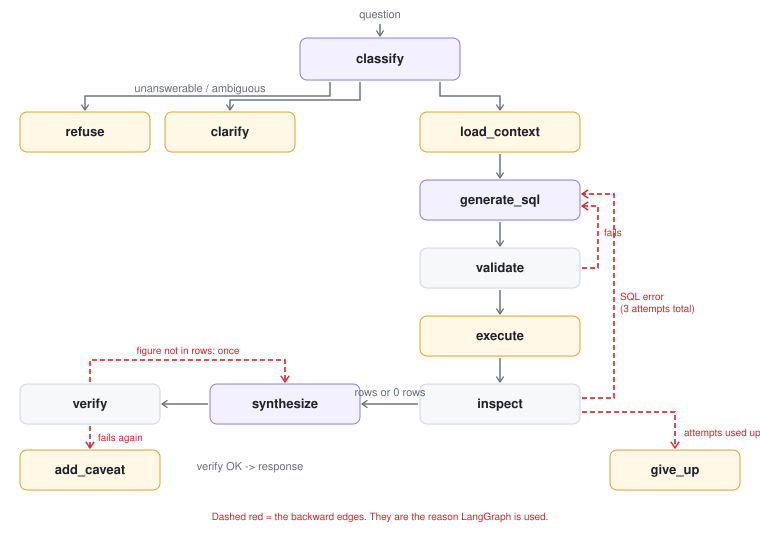

In [13]:
diagram("""
<text class="ts" x="380" y="18" text-anchor="middle">question</text>
<path d="M380 24 L380 36" class="arr" marker-end="url(#a)"/>
<rect x="300" y="38" width="160" height="42" rx="7" class="bxa"/><text class="th" x="380" y="63" text-anchor="middle">classify</text>
<rect x="20" y="112" width="130" height="40" rx="7" class="bxw"/><text class="th" x="85" y="136" text-anchor="middle">refuse</text>
<rect x="165" y="112" width="130" height="40" rx="7" class="bxw"/><text class="th" x="230" y="136" text-anchor="middle">clarify</text>
<path d="M330 82 L330 96 L85 96 L85 110" class="arr" marker-end="url(#a)"/>
<path d="M360 82 L360 100 L230 100 L230 110" class="arr" marker-end="url(#a)"/>
<path d="M440 82 L440 96 L500 96 L500 110" class="arr" marker-end="url(#a)"/>
<text class="ts" x="200" y="92" text-anchor="middle">unanswerable / ambiguous</text>
<rect x="420" y="112" width="160" height="40" rx="7" class="bxw"/><text class="th" x="500" y="136" text-anchor="middle">load_context</text>
<rect x="420" y="180" width="160" height="40" rx="7" class="bxa"/><text class="th" x="500" y="204" text-anchor="middle">generate_sql</text>
<rect x="420" y="248" width="160" height="40" rx="7" class="bx"/><text class="th" x="500" y="272" text-anchor="middle">validate</text>
<rect x="420" y="316" width="160" height="40" rx="7" class="bxw"/><text class="th" x="500" y="340" text-anchor="middle">execute</text>
<rect x="420" y="384" width="160" height="40" rx="7" class="bx"/><text class="th" x="500" y="408" text-anchor="middle">inspect</text>
<path d="M500 154 L500 178" class="arr" marker-end="url(#a)"/>
<path d="M500 222 L500 246" class="arr" marker-end="url(#a)"/>
<path d="M500 290 L500 314" class="arr" marker-end="url(#a)"/>
<path d="M500 358 L500 382" class="arr" marker-end="url(#a)"/>
<path d="M582 268 L598 268 L598 206 L582 206" class="arrR" marker-end="url(#ar)"/>
<path d="M582 398 L614 398 L614 194 L582 194" class="arrR" marker-end="url(#ar)"/>
<text class="lbl" x="604" y="236" text-anchor="start">fails</text>
<text class="lbl" x="620" y="300" text-anchor="start">SQL error</text>
<text class="lbl" x="620" y="312" text-anchor="start">(3 attempts total)</text>
<rect x="610" y="450" width="130" height="40" rx="7" class="bxw"/><text class="th" x="675" y="474" text-anchor="middle">give_up</text>
<path d="M582 412 L675 412 L675 448" class="arrR" marker-end="url(#ar)"/>
<text class="lbl" x="684" y="436" text-anchor="start">attempts used up</text>
<rect x="210" y="384" width="150" height="40" rx="7" class="bxa"/><text class="th" x="285" y="408" text-anchor="middle">synthesize</text>
<rect x="20" y="384" width="140" height="40" rx="7" class="bx"/><text class="th" x="90" y="408" text-anchor="middle">verify</text>
<path d="M418 404 L362 404" class="arr" marker-end="url(#a)"/>
<path d="M208 404 L162 404" class="arr" marker-end="url(#a)"/>
<text class="ts" x="390" y="396" text-anchor="middle">rows or 0 rows</text>
<path d="M90 382 L90 360 L285 360 L285 382" class="arrR" marker-end="url(#ar)"/>
<text class="lbl" x="188" y="354" text-anchor="middle">figure not in rows: once</text>
<rect x="20" y="450" width="140" height="40" rx="7" class="bxw"/><text class="th" x="90" y="474" text-anchor="middle">add_caveat</text>
<path d="M90 426 L90 448" class="arrR" marker-end="url(#ar)"/>
<text class="lbl" x="98" y="441" text-anchor="start">fails again</text>
<text class="ts" x="250" y="470" text-anchor="middle">verify OK -&gt; response</text>
<text class="lbl" x="380" y="520" text-anchor="middle">Dashed red = the backward edges. They are the reason LangGraph is used.</text>
""", width=760, height=535)

To watch a retry happen without paying for an LLM, a **scripted LLM** returns prepared
answers. The first SQL misspells the region; the literal check rejects it; the graph goes
back to `generate_sql` with the reason; the second SQL works. The database calls are real.

In [14]:
from askauto.agent.graph import build_graph, run_agent
from askauto.agent.nodes import AgentNodes
from askauto.agent.state import Answer, Classification, SQLPlan

class ScriptedLLM:
    """Stands in for Groq: returns prepared answers, so this cell costs nothing."""
    def __init__(self, **queues):
        self.queues = {call: list(items) for call, items in queues.items()}
    async def complete(self, call, messages, schema):
        return self.queues[call].pop(0)

QUERY = ("SELECT COUNT(*) AS units FROM sales JOIN dealers USING (dealer_id) "
         "WHERE region = '{}' AND strftime('%Y', sale_date) = '2024'")
llm = ScriptedLLM(
    classify=[Classification(label="answerable", reason="sales by region and year",
                             clarifying_question=None)],
    generate_sql=[SQLPlan(sql=QUERY.format("North East"), tables_used=["sales", "dealers"],
                          assumptions=[]),
                  SQLPlan(sql=QUERY.format("Northeast"), tables_used=["sales", "dealers"],
                          assumptions=["'North East' -> 'Northeast'"])],
    synthesize=[Answer(text="The Northeast region sold 351 cars in 2024.")],
)

async with McpTools.connect(create_server(settings)) as tools:
    startup = await tools.get_schema_context()
    graph = build_graph(AgentNodes(llm, tools, startup))
    state = await run_agent(graph, "How many cars did the North East region sell in 2024?")

for step in state.trace:
    print(" ", step[:150])
print("\nstatus:", state.status, "| answer:", state.answer.text)

  classify: answerable - sales by region and year
  load_context: 3 tables, 15 glossary terms (mode=full)
  generate_sql: attempt 1
  validate: rejected by validator: 'North East' is not an allowed value for region; it would match no rows. Use one of: 'Midwest', 'Northeast', 'Southea
  generate_sql: attempt 2
  validate: ok
  execute: 1 rows
  inspect: rows
  synthesize: 43 chars
  verify: 1/1 figures found in rows

status: answered | answer: The Northeast region sold 351 cars in 2024.


## Step 10 - The API: `src/askauto/api.py`

`create_app()` builds the FastAPI app. Its **lifespan** runs once at startup: settings ->
open one MCP session -> cache the schema -> build the graph. A request only runs the graph.

| Endpoint | Does |
|---|---|
| `GET /` | the plain web page |
| `POST /ask` | `{"question"}` -> answer, sql, assumptions, rows, trace, latency_ms, status |
| `GET /health` | a real round trip to the MCP server |

Errors become clean JSON: LLM failure -> 502, data service failure -> 503, empty question
-> 422. Below, the real app runs in-process with the scripted LLM. (The latency is tiny
because the scripted LLM answers instantly; with Groq a question takes 2-4 s.)

In [15]:
from fastapi.testclient import TestClient
from askauto.api import create_app

llm = ScriptedLLM(
    classify=[Classification(label="answerable", reason="covered", clarifying_question=None)],
    generate_sql=[SQLPlan(
        sql="SELECT SUM(sale_price - discount_amount) AS net_revenue FROM sales "
            "WHERE strftime('%Y', sale_date) = '2025'",
        tables_used=["sales"], assumptions=["last year = 2025", "revenue = net revenue"])],
    synthesize=[Answer(text="Net revenue for 2025 was $52.2M.")],
)
with TestClient(create_app(settings, provider=llm, mcp_target=create_server(settings))) as client:
    body = client.post("/ask", json={"question": "What was our net revenue last year?"}).json()

body["trace"] = [t.split(":")[0] for t in body["trace"]]
print(json.dumps(body, indent=2))

{
  "answer": "Net revenue for 2025 was $52.2M.",
  "sql": "SELECT SUM(sale_price - discount_amount) AS net_revenue FROM sales WHERE STRFTIME('%Y', sale_date) = '2025' LIMIT 500",
  "assumptions": [
    "last year = 2025",
    "revenue = net revenue"
  ],
  "rows": [
    {
      "net_revenue": 52228431.6
    }
  ],
  "trace": [
    "classify",
    "load_context",
    "generate_sql",
    "validate",
    "execute",
    "inspect",
    "synthesize",
    "verify"
  ],
  "latency_ms": 74,
  "status": "answered"
}


## Step 11 - The front ends

Both are **thin clients**: they only call `POST /ask` and `GET /health`.

| | `src/askauto/web/index.html` | `frontend/streamlit_app.py` |
|---|---|---|
| Open at | http://localhost:8000/ | http://localhost:8501 |
| Runs in | the browser (served by the API) | its own Python process |
| Built with | plain HTML + JavaScript | Streamlit |
| Notable | text inserted with `textContent`, never as HTML | dollar signs escaped so money isn't rendered as maths |

```bash
.venv/Scripts/python -m uvicorn askauto.api:app --port 8000      # then open http://localhost:8000/
.venv/Scripts/python -m streamlit run frontend/streamlit_app.py  # optional second UI
```

## Step 12 - Proving it works: `evals/`

**`questions.yaml`** has 25 questions. Each answerable one has reference SQL; its expected
values were filled **by running that SQL**, never typed by hand.

**`run_evals.py`** does four things:
1. re-runs every reference query (through MCP) and stops if the data drifted
2. asks each question through the real app, 40 s apart (Groq rate limit)
3. scores status, values, labels, and the trap SQL patterns
4. prints the scorecard and saves JSON to `evals/results/`

A value matches at the precision the agent shows, within 1%, so rounding is fine but a
wrong figure isn't:

In [16]:
spec = importlib.util.spec_from_file_location("run_evals", ROOT / "evals" / "run_evals.py")
run_evals = importlib.util.module_from_spec(spec)
spec.loader.exec_module(run_evals)

for cell, expected, note in [
    (52228431.6, 52228431.6, "exact"),
    (52228432, 52228431.6, "rounded to whole dollars"),
    (0.36, 0.362221, "rate rounded to 2 places"),
    (36.22, 0.362221, "rate as a percentage"),
    (54134516.45, 52228431.6, "gross instead of net"),
    (350, 351, "off by one"),
]:
    verdict = "match" if run_evals.number_matches(cell, expected) else "NO MATCH"
    print(f"{cell!r:>14} vs {expected!r:<12} {verdict:9} ({note})")

    52228431.6 vs 52228431.6   match     (exact)
      52228432 vs 52228431.6   match     (rounded to whole dollars)
          0.36 vs 0.362221     match     (rate rounded to 2 places)
         36.22 vs 0.362221     match     (rate as a percentage)
   54134516.45 vs 52228431.6   NO MATCH  (gross instead of net)
           350 vs 351          NO MATCH  (off by one)


## Step 13 - The tests: `tests/`

**158 tests**, no network, about 15 seconds: `.venv/Scripts/python -m pytest -q`

| File | Tests |
|---|---|
| `test_agent.py` | 14 |
| `test_api.py` | 10 |
| `test_build_database.py` | 10 |
| `test_build_metadata.py` | 15 |
| `test_evals.py` | 17 |
| `test_literals.py` | 14 |
| `test_mcp_server.py` | 13 |
| `test_providers.py` | 17 |
| `test_sql_guard.py` | 35 |
| `test_verify.py` | 13 |

| File | What it proves |
|---|---|
| `test_build_database.py` | the DDL keeps its foreign keys; both traps exist; same seed = same data |
| `test_build_metadata.py` | glossary aliases match; allowed values exact; bad YAML fails loudly |
| `test_sql_guard.py` | every unsafe statement, table and column is rejected, with a reason |
| `test_mcp_server.py` | the real MCP protocol: zero rows vs errors, timeout recovery, read-only |
| `test_providers.py` | temperatures, strict schema, retries, which errors are not retried |
| `test_literals.py` / `test_verify.py` | the two deterministic checks |
| `test_agent.py` | **each backward edge is forced to fire**; prompts contain no hard-coded schema |
| `test_api.py` | the contract, one MCP session for all requests, 502/422/503, the web page |
| `test_evals.py` | the eval scoring rules |

The rule throughout: **the LLM is always mocked in tests**. Live behaviour is checked
separately - by hand, by the smoke test, and by the eval set.

## Step 14 - How it was built: `CLAUDE.md` and `.claude/`

The project was built with Claude Code, one stage per session, using four mechanisms:

| Mechanism | File(s) | Loads | Used for |
|---|---|---|---|
| Project memory | `CLAUDE.md` | every session | rules that must always hold |
| Path rules | `.claude/rules/*.md` | when matching files are touched | layer conventions (agent, MCP, tests) |
| Skills | `.claude/skills/stage-done`, `trap-check` | on demand | repeatable checklists |
| Hook | `.claude/hooks/guard_imports.py` | before every file edit | **blocks** sqlite3 outside `mcp_server/`, groq outside `providers/` |

The key idea: **CLAUDE.md persuades, hooks enforce.** `docs/PROGRESS.md` is the
cross-session log - every decision, deviation and verified command is recorded there.

## Step 15 - One question through every function

"What was our net revenue last year?", from the click to the screen:

| # | Where | Function | What happens |
|---|---|---|---|
| 1 | `web/index.html` | `ask()` | browser sends `POST /ask` |
| 2 | `api.py` | `ask()` | starts the clock, calls `run_agent` |
| 3 | `agent/graph.py` | `run_agent()` | starts the graph with a fresh `AgentState` |
| 4 | `agent/nodes.py` | `classify()` | `classify_messages()` -> `provider.complete("classify", ...)` |
| 5 | `providers/groq_provider.py` | `complete()` | Groq call, strict schema -> `Classification` |
| 6 | `agent/graph.py` | `after_classify()` | answerable -> `load_context` |
| 7 | `mcp_client.py` | `get_schema_context()` | cached since startup - no round trip |
| 8 | `agent/nodes.py` | `generate_sql()` | `sql_messages()` + `render_schema()` -> `SQLPlan` |
| 9 | `agent/nodes.py` | `validate()` | `guard_sql()` + `check_literals()` |
| 10 | `agent/graph.py` | `after_validate()` | ok -> `execute` |
| 11 | `mcp_client.py` -> `mcp_server/server.py` | `run_sql()` | guard **again**, then `db.fetch_with_timeout()` |
| 12 | `agent/nodes.py` | `inspect()` | 1 row -> `rows` |
| 13 | `agent/nodes.py` | `synthesize()` | `synthesize_messages()` -> `Answer` |
| 14 | `agent/verify.py` | `verify_answer()` | "\$52.2M" found in the rows -> status `answered` |
| 15 | `api.py` | `to_response()` | answer + SQL + rows + trace + latency as JSON |
| 16 | `web/index.html` | `renderResult()` | the answer card you see |

**Next steps for learning:** change a glossary entry in `metadata/glossary.yaml`, rebuild
with `scripts/build_metadata.py`, and watch the SQL change. Then break the YAML on purpose
and read the error. That is the fastest way to feel how the pieces connect.